<a href="https://colab.research.google.com/github/kashvi613/MovieRecommendationSystem/blob/main/MovieRecommendationSystem.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!wget -q https://files.grouplens.org/datasets/movielens/ml-25m.zip
!unzip -q ml-25m.zip
!ls ml-25m

genome-scores.csv  links.csv   ratings.csv  tags.csv
genome-tags.csv    movies.csv  README.txt


In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!unzip -q "/content/drive/MyDrive/MovieRec/ml-25m.zip" -d /content/
!ls /content/ml-25m

replace /content/ml-25m/tags.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: N
genome-scores.csv  links.csv   ratings.csv  tags.csv
genome-tags.csv    movies.csv  README.txt


In [4]:
import pandas as pd
import numpy as np

ratings = pd.read_csv(
    '/content/ml-25m/ratings.csv',
    dtype={'userId': 'int32', 'movieId': 'int32', 'rating': 'float32', 'timestamp': 'int32'}
)
movies = pd.read_csv('/content/ml-25m/movies.csv')

print("ratings:", ratings.shape)
print("movies:", movies.shape)
ratings.head()

ratings: (25000095, 4)
movies: (62423, 3)


,userId,movieId,rating,timestamp
0,1,296,5.0,1147880044
1,1,306,3.5,1147868817
2,1,307,5.0,1147868828
3,1,665,5.0,1147878820
4,1,899,3.5,1147868510


In [5]:
print("Users:", ratings['userId'].nunique())
print("Movies rated:", ratings['movieId'].nunique())
print("Rating range:", ratings['rating'].min(), "to", ratings['rating'].max())

Users: 162541
Movies rated: 59047
Rating range: 0.5 to 5.0


In [6]:
# 1. Movies jinke kam se kam 100 ratings hain
movie_counts = ratings['movieId'].value_counts()
df = ratings[ratings['movieId'].isin(movie_counts[movie_counts >= 100].index)]

# 2. Users jinke kam se kam 50 ratings hain
user_counts = df['userId'].value_counts()
good_users = user_counts[user_counts >= 50].index
df = df[df['userId'].isin(good_users)]

# 3. 15,000 users sample karo
sampled_users = pd.Series(good_users).sample(n=15000, random_state=42)
df = df[df['userId'].isin(sampled_users)].copy()

# 4. Sampling ke baad bahut kam ratings wali movies hata do
movie_counts = df['movieId'].value_counts()
df = df[df['movieId'].isin(movie_counts[movie_counts >= 20].index)].copy()

df = df.reset_index(drop=True)
print(df.shape)

(3303977, 4)


In [7]:
print("Rows:", len(df))
print("Users:", df['userId'].nunique())
print("Movies:", df['movieId'].nunique())
print("Sparsity: {:.2f}%".format(100 * (1 - len(df) / (df['userId'].nunique() * df['movieId'].nunique()))))
print("Min ratings per user:", df['userId'].value_counts().min())
print("Min ratings per movie:", df['movieId'].value_counts().min())

Rows: 3303977
Users: 15000
Movies: 9155
Sparsity: 97.59%
Min ratings per user: 47
Min ratings per movie: 20


In [8]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate (user, movie) pairs:", df.duplicated(subset=['userId', 'movieId']).sum())

Duplicate rows: 0
Duplicate (user, movie) pairs: 0


In [9]:
print(df.isnull().sum())
print(movies.isnull().sum())

userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
movieId    0
title      0
genres     0
dtype: int64


In [10]:
df['date'] = pd.to_datetime(df['timestamp'], unit='s')
df['rating_year'] = df['date'].dt.year
df[['userId', 'movieId', 'rating', 'date', 'rating_year']].head()

,userId,movieId,rating,date,rating_year
0,8,1,4.0,1998-03-21 15:01:57,1998
1,8,3,4.0,1998-03-21 15:08:26,1998
2,8,6,3.0,1998-03-21 14:15:13,1998
3,8,7,1.0,1998-03-21 15:00:14,1998
4,8,10,4.0,1998-03-21 14:22:49,1998


In [11]:
movies_small = movies[movies['movieId'].isin(df['movieId'].unique())].copy()
print(movies_small.shape)

(9155, 3)


In [12]:
movies_small['year'] = movies_small['title'].str.extract(r'\((\d{4})\)\s*$').astype('float')
print("Missing year:", movies_small['year'].isnull().sum())
movies_small['clean_title'] = movies_small['title'].str.replace(r'\s*\(\d{4}\)\s*$', '', regex=True)
movies_small.head()

Missing year: 12


,movieId,title,genres,year,clean_title
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy,1995.0,Toy Story
1,2,Jumanji (1995),Adventure|Children|Fantasy,1995.0,Jumanji
2,3,Grumpier Old Men (1995),Comedy|Romance,1995.0,Grumpier Old Men
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance,1995.0,Waiting to Exhale
4,5,Father of the Bride Part II (1995),Comedy,1995.0,Father of the Bride Part II


In [13]:
movies_small['year'] = movies_small['year'].fillna(movies_small['year'].median())

In [14]:
movies_small['genres_list'] = movies_small['genres'].str.split('|')
movies_small['genres_list'] = movies_small['genres_list'].apply(
    lambda g: [] if g == ['(no genres listed)'] else g
)
movies_small[['clean_title', 'year', 'genres_list']].head()

,clean_title,year,genres_list
0,Toy Story,1995.0,"[Adventure, Animation, Children, Comedy, Fantasy]"
1,Jumanji,1995.0,"[Adventure, Children, Fantasy]"
2,Grumpier Old Men,1995.0,"[Comedy, Romance]"
3,Waiting to Exhale,1995.0,"[Comedy, Drama, Romance]"
4,Father of the Bride Part II,1995.0,[Comedy]


In [15]:
data = df.merge(movies_small[['movieId', 'clean_title', 'year', 'genres_list']], on='movieId', how='left')
print(data.shape)
data.head()

(3303977, 9)


,userId,movieId,rating,timestamp,date,rating_year,clean_title,year,genres_list
0,8,1,4.0,890492517,1998-03-21 15:01:57,1998,Toy Story,1995.0,"[Adventure, Animation, Children, Comedy, Fantasy]"
1,8,3,4.0,890492906,1998-03-21 15:08:26,1998,Grumpier Old Men,1995.0,"[Comedy, Romance]"
2,8,6,3.0,890489713,1998-03-21 14:15:13,1998,Heat,1995.0,"[Action, Crime, Thriller]"
3,8,7,1.0,890492414,1998-03-21 15:00:14,1998,Sabrina,1995.0,"[Comedy, Romance]"
4,8,10,4.0,890490169,1998-03-21 14:22:49,1998,GoldenEye,1995.0,"[Action, Adventure, Thriller]"


In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
sns.set_style('whitegrid')

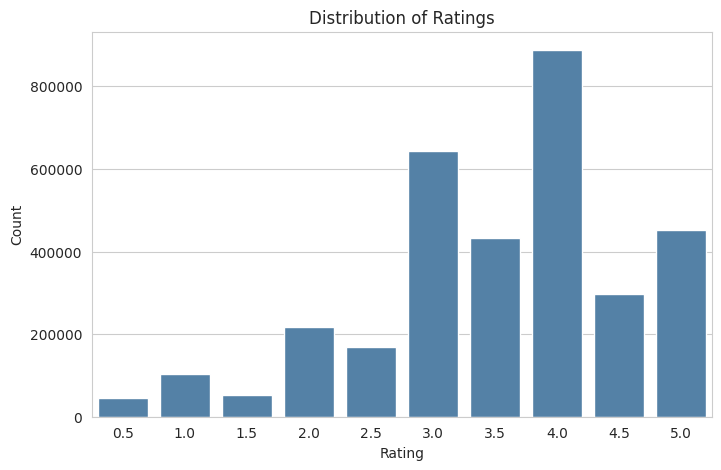

In [17]:
plt.figure(figsize=(8,5))
sns.countplot(data=data, x='rating', color='steelblue')
plt.title('Distribution of Ratings')
plt.xlabel('Rating'); plt.ylabel('Count')
plt.show()

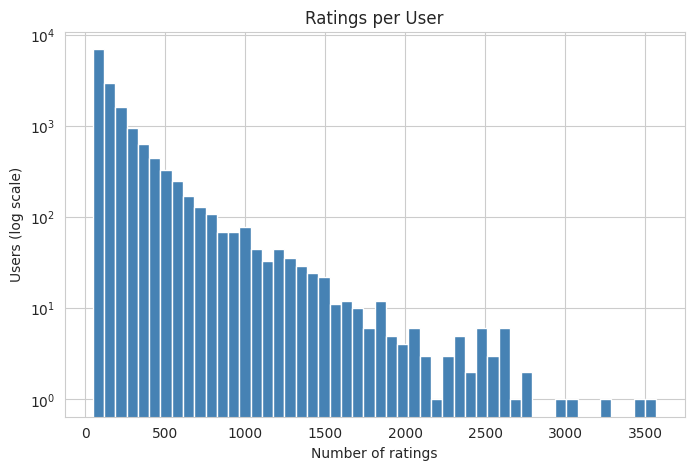

count    15000.000000
mean       220.265133
std        267.631377
min         47.000000
25%         77.000000
50%        128.000000
75%        245.000000
max       3572.000000
Name: count, dtype: float64


In [21]:
user_counts = data['userId'].value_counts()
plt.figure(figsize=(8,5))
plt.hist(user_counts, bins=50, color='steelblue', edgecolor='white')
plt.yscale('log')
plt.title('Ratings per User')
plt.xlabel('Number of ratings'); plt.ylabel('Users (log scale)')
plt.show()
print(user_counts.describe())

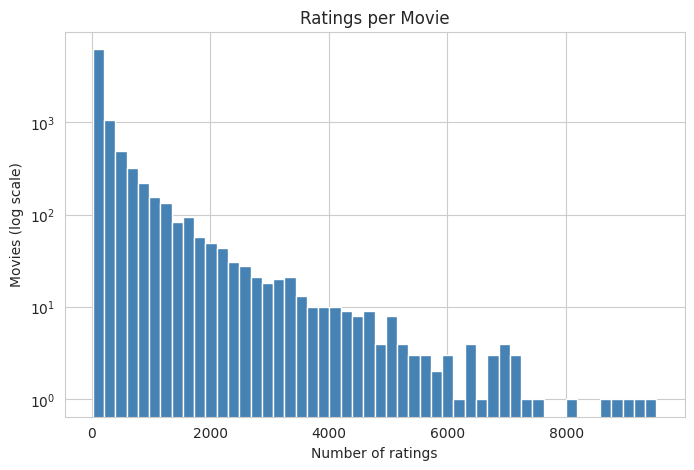

In [22]:
movie_counts = data['movieId'].value_counts()
plt.figure(figsize=(8,5))
plt.hist(movie_counts, bins=50, color='steelblue', edgecolor='white')
plt.yscale('log')
plt.title('Ratings per Movie')
plt.xlabel('Number of ratings'); plt.ylabel('Movies (log scale)')
plt.show()

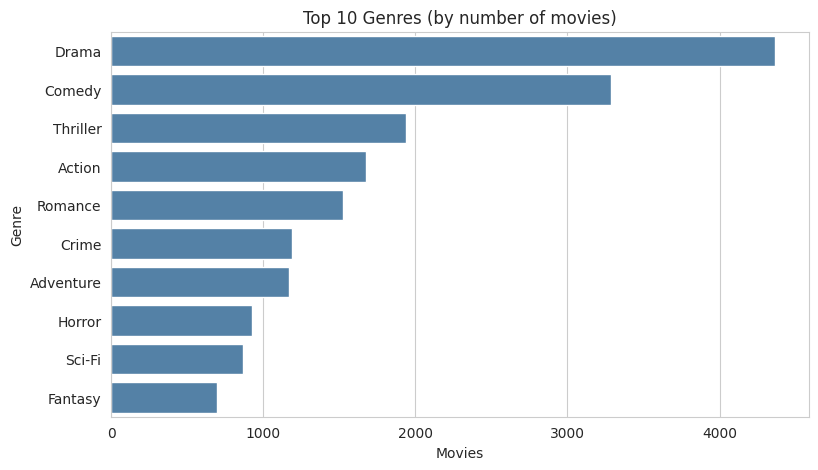

In [24]:
genre_counts = Counter(g for lst in movies_small['genres_list'] for g in lst)
top = pd.DataFrame(genre_counts.most_common(10), columns=['Genre', 'Movies'])
plt.figure(figsize=(9,5))
sns.barplot(data=top, x='Movies', y='Genre', color='steelblue')
plt.title('Top 10 Genres (by number of movies)')
plt.show()

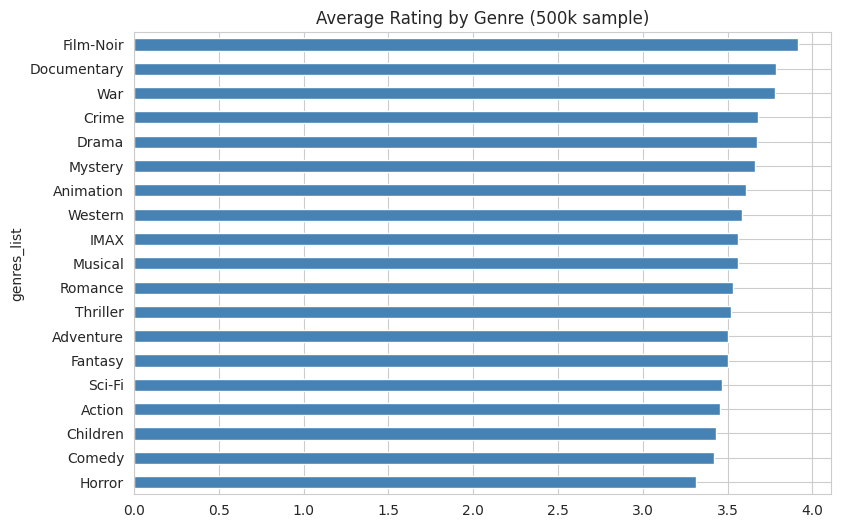

In [25]:
sample = data.sample(500000, random_state=42)
exploded = sample[['rating', 'genres_list']].explode('genres_list').dropna()
avg = exploded.groupby('genres_list')['rating'].mean().sort_values()
avg.plot(kind='barh', color='steelblue', figsize=(9,6))
plt.title('Average Rating by Genre (500k sample)'); plt.show()

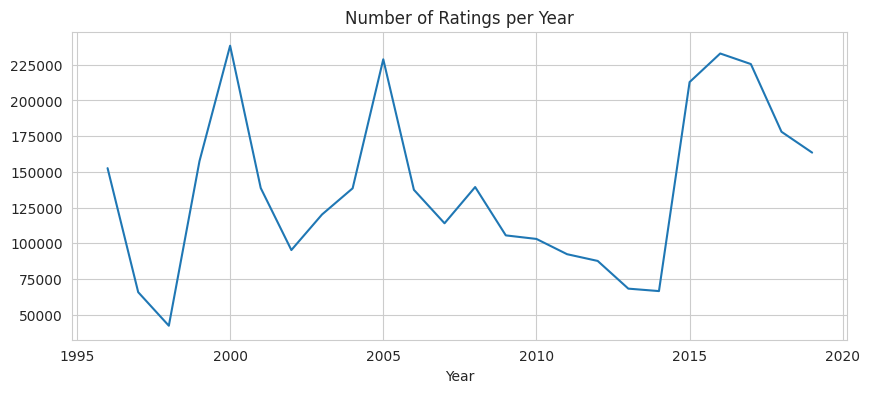

In [26]:
data['rating_year'].value_counts().sort_index().plot(kind='line', figsize=(10,4))
plt.title('Number of Ratings per Year'); plt.xlabel('Year'); plt.show()